# EDA: фонетический анализ корпуса RUSLAN (лаба 3)

Разведочный анализ артефактов этапа 1:
- `tokens_phones.csv` — токены + фонемы (без пауз)
- `tokens_phones_sil.csv` — токены + фонемы (с паузами)
- `lexicon.csv` — словарь произношений по train
- `russian_mfa.dict` — оригинальный MFA-словарь
- `common/phones_mfa.txt` — целевой инвентарь фонем

Цель: ответить на 6 вопросов задания и принять решения по архитектуре G2P.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import unicodedata
import glob
from praatio import textgrid

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA = Path('data')
ALIGN = Path('../../data/RUSLAN_22050_align_v2')

print('ok')

ok


In [7]:
print('cwd:', Path.cwd())
print('DATA:', DATA.resolve())
print()
print('data/ exists:', DATA.exists())
print('tokens_phones.csv exists:', (DATA / 'tokens_phones.csv').exists())
print('tokens_phones_sil.csv exists:', (DATA / 'tokens_phones_sil.csv').exists())
print('lexicon.csv exists:', (DATA / 'lexicon.csv').exists())
print('mfa_dict.csv exists:', (DATA / 'mfa_dict.csv').exists())
print()
print('phones_mfa.txt exists:', Path('../../common/phones_mfa.txt').exists())
print('ALIGN dir exists:', ALIGN.exists())


cwd: /mnt/d/TTS_ITMO/tts_labs_itmo/labs/lab3_g2p
DATA: /mnt/d/TTS_ITMO/tts_labs_itmo/labs/lab3_g2p/data

data/ exists: True
tokens_phones.csv exists: True
tokens_phones_sil.csv exists: True
lexicon.csv exists: True
mfa_dict.csv exists: True

phones_mfa.txt exists: True
ALIGN dir exists: True


In [8]:
tokens = pd.read_csv(DATA / 'tokens_phones.csv', sep='|', quoting=3)
tokens_sil = pd.read_csv(DATA / 'tokens_phones_sil.csv', sep='|', quoting=3)
lexicon = pd.read_csv(DATA / 'lexicon.csv', sep='|', quoting=3)
mfa = pd.read_csv(DATA / 'mfa_dict.csv', sep='|', quoting=3)

target_phones = set(
    Path('../../common/phones_mfa.txt').read_text(encoding='utf-8').split()
)

print(f'tokens:        {len(tokens):>8} строк  ({tokens["id"].nunique()} предложений)')
print(f'tokens_sil:    {len(tokens_sil):>8} строк')
print(f'lexicon:       {len(lexicon):>8} строк  ({lexicon["word"].nunique()} уникальных слов)')
print(f'mfa_dict:      {len(mfa):>8} строк  ({mfa["word"].nunique()} уникальных слов)')
print(f'target phones: {len(target_phones):>8} фонем (вкл. <SIL>)')
print()
print(tokens.head())

tokens:          245939 строк  (21281 предложений)
tokens_sil:      305350 строк
lexicon:          41839 строк  (41131 уникальных слов)
mfa_dict:        160509 строк  (153486 уникальных слов)
target phones:       56 фонем (вкл. <SIL>)

              id  token_id      token                phones   set
0  000000_RUSLAN         0          с                    s̪  test
1  000000_RUSLAN         1  тревожным  t̪ rʲ ɪ v o ʐ n̪ ɨ m  test
2  000000_RUSLAN         2   чувством      tɕ u s̪ t̪ v ə m  test
3  000000_RUSLAN         3     берусь           bʲ ɪ r u sʲ  test
4  000000_RUSLAN         4          я                   j a  test


In [9]:
# Собираем все фонемы из train-части (без <SIL> — его тут и нет)
train_tokens = tokens[tokens['set'] == 'train'].copy()

all_phones = []
for phones_str in train_tokens['phones'].dropna():
    all_phones.extend(phones_str.split())

phone_counts = Counter(all_phones)
df_phones = pd.DataFrame(
    phone_counts.most_common(),
    columns=['phone', 'count']
)
df_phones['freq_pct'] = (df_phones['count'] / df_phones['count'].sum() * 100).round(3)

print(f'Всего фонемных вхождений (train): {len(all_phones):,}')
print(f'Уникальных фонем: {len(df_phones)}')
print()
print('ТОП-20 самых частых:')
print(df_phones.head(20).to_string(index=False))
print()
print('ТОП-10 самых редких:')
print(df_phones.tail(10).to_string(index=False))

Всего фонемных вхождений (train): 1,102,333
Уникальных фонем: 56

ТОП-20 самых частых:
phone  count  freq_pct
    ɪ  89299     8.101
    ə  83644     7.588
    ɐ  57961     5.258
    a  48957     4.441
   t̪  48094     4.363
    j  42950     3.896
   n̪  42806     3.883
    e  38624     3.504
   s̪  36801     3.338
    r  35612     3.231
    ɨ  33872     3.073
    o  32911     2.986
    i  32763     2.972
    v  32455     2.944
    k  30191     2.739
    ɫ  28800     2.613
    m  26228     2.379
    ʎ  25841     2.344
    ɲ  23701     2.150
    p  22934     2.080

ТОП-10 самых редких:
phone  count  freq_pct
    ʉ   2145     0.195
  spn   1831     0.166
   fʲ   1630     0.148
    ɵ    839     0.076
    ç    461     0.042
   tʂ    259     0.023
   dʐ    189     0.017
    ɣ     25     0.002
    ʑ     16     0.001
 d̪z̪      1     0.000


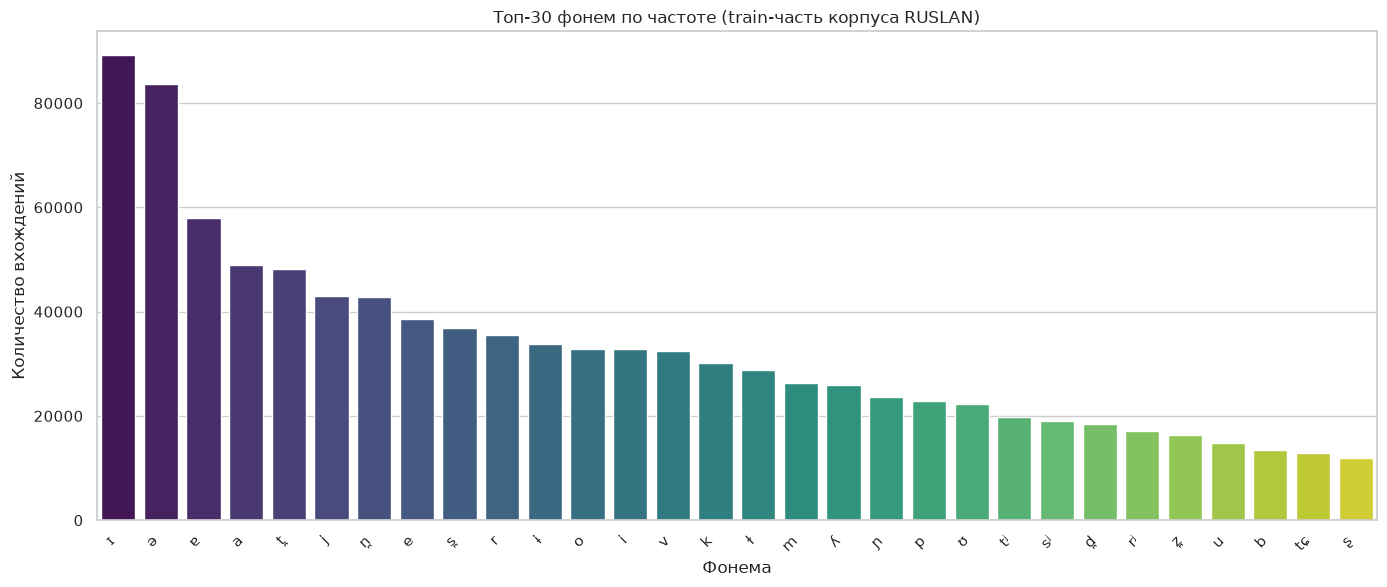

In [10]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(
    data=df_phones.head(30),
    x='phone', y='count',
    hue='phone', legend=False,
    palette='viridis', ax=ax,
)
ax.set_title('Топ-30 фонем по частоте (train-часть корпуса RUSLAN)')
ax.set_xlabel('Фонема')
ax.set_ylabel('Количество вхождений')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Длительности фонем

Длительности берём из оригинальных TextGrid'ов (в `tokens_phones.csv` их нет).
Для статистики используем выборку из 3000 файлов (~13% корпуса) — этого достаточно.
В G2P длительности не используются: их моделирует акустическая модель (лаба 4).

In [12]:
def collect_durations(align_dir, max_files=None):
    """Собирает длительности фонем из TextGrid'ов.

    Returns:
        dict: {phone: [duration_seconds, ...]}
    """
    durations = {}
    files = sorted(glob.glob(str(align_dir / '*.TextGrid')))
    if max_files:
        files = files[:max_files]
    for path in files:
        try:
            tg = textgrid.openTextgrid(path, True)
        except Exception:
            continue
        phone_tier = tg.tiers[1]
        for entry in phone_tier.entries:
            if not entry.label:
                continue
            label = unicodedata.normalize('NFC', entry.label).replace('ː', '')
            durations.setdefault(label, []).append(entry.end - entry.start)
    return durations

durations = collect_durations(ALIGN, max_files=3000)

print(f'Файлов обработано: 3000')
print(f'Уникальных фонем (включая spn): {len(durations)}')
print(f'Всего фонемных вхождений: {sum(len(v) for v in durations.values()):,}')

Файлов обработано: 3000
Уникальных фонем (включая spn): 54
Всего фонемных вхождений: 100,473


In [13]:
stats = []
for phone, durs in durations.items():
    if len(durs) < 10:
        continue
    stats.append({
        'phone': phone,
        'count': len(durs),
        'mean_ms': np.mean(durs) * 1000,
        'std_ms': np.std(durs) * 1000,
        'median_ms': np.median(durs) * 1000,
        'min_ms': np.min(durs) * 1000,
        'max_ms': np.max(durs) * 1000,
    })

df_dur = pd.DataFrame(stats).sort_values('mean_ms', ascending=False).reset_index(drop=True)
print(f'Фонем со статистикой (>=10 вхождений): {len(df_dur)}')
print()
print(df_dur.to_string(index=False, float_format=lambda x: f'{x:.1f}'))

Фонем со статистикой (>=10 вхождений): 52

phone  count  mean_ms  std_ms  median_ms  min_ms  max_ms
   dʐ     26    170.8    37.8      175.0    70.0   260.0
    ɕ    360    167.9    31.3      170.0    80.0   310.0
   tʂ     23    158.7    23.1      150.0   110.0   220.0
    ç     29    152.1    27.8      150.0    90.0   200.0
 t̪s̪    438    142.9    42.6      147.0    30.0   330.0
   sʲ   1609    139.4    33.0      140.0    30.0   310.0
   tɕ   1210    134.9    29.4      140.0    30.0   293.4
    ʂ    990    130.2    30.9      130.0    40.0   320.0
   tʲ   1937    122.3    37.0      120.0    30.0   300.0
    x    734    120.4    46.0      120.0    25.7   320.0
   fʲ    137    119.4    36.4      120.0    10.0   210.0
   zʲ    298    118.7    31.0      110.0    50.0   270.0
   s̪   3418    118.1    37.1      110.0    30.0   430.0
    ɛ    633    113.4    50.0      100.0    30.0   370.0
    ɵ     84    112.7    65.6       90.0    50.0   370.0
    a   4486    108.6    47.4      100.0    3

In [14]:
VOWELS = {'a', 'e', 'i', 'o', 'u', 'ɨ', 'ɛ', 'æ', 'ɐ', 'ə', 'ɪ', 'ʊ', 'ɵ', 'ʉ'}
CONSONANTS = set(df_dur['phone']) - VOWELS

df_dur['type'] = df_dur['phone'].apply(
    lambda p: 'vowel' if p in VOWELS else 'consonant'
)

print(df_dur.groupby('type')['mean_ms'].agg(['count', 'mean', 'median']).round(1))

           count   mean  median
type                           
consonant     38  108.2   102.6
vowel         14   82.0    92.6


In [15]:
VOWELS_STRESSED = {'a', 'o', 'e', 'i', 'u', 'ɛ', 'æ', 'ɵ'}    # полные гласные
PLOSIVES = {'p', 'pʲ', 'b', 'bʲ', 't̪', 'tʲ', 'd̪', 'dʲ', 'k', 'ɡ', 'c', 'ɟ'}

df_dur['group'] = 'other'
df_dur.loc[df_dur['phone'].isin(VOWELS_STRESSED), 'group'] = 'stressed_vowel'
df_dur.loc[df_dur['phone'].isin(PLOSIVES), 'group'] = 'plosive'

print(df_dur[df_dur['group'] != 'other'].groupby('group')['mean_ms'].agg(['count', 'mean', 'median']).round(1))
print()
print('Детально по группам:')
print(df_dur[df_dur['group'] == 'stressed_vowel'][['phone', 'mean_ms']].to_string(index=False))
print()
print(df_dur[df_dur['group'] == 'plosive'][['phone', 'mean_ms']].to_string(index=False))

                count   mean  median
group                               
plosive            12   96.2    95.6
stressed_vowel      8  102.1   101.0

Детально по группам:
phone    mean_ms
    ɛ 113.412322
    ɵ 112.684107
    a 108.646533
    o 102.046556
    æ  99.927536
    u  95.342180
    i  93.127584
    e  92.006429

phone    mean_ms
   tʲ 122.302858
   bʲ 107.642045
   dʲ 104.803719
    ɟ 104.448980
    c  99.956710
    k  96.382325
   pʲ  94.859155
    b  94.059574
    ɡ  86.271368
   t̪  83.692364
    p  80.739822
   d̪  79.698046


In [16]:
# Смотрим хвост распределения
rare = df_phones[df_phones['count'] < 500].copy()
print(f'Редких фонем (<500 вхождений в train): {len(rare)}')
print()
print(rare.to_string(index=False))
print()

# Совсем редкие
very_rare = df_phones[df_phones['count'] < 50]
print(f'Очень редких фонем (<50 вхождений): {len(very_rare)}')
print(very_rare.to_string(index=False))

Редких фонем (<500 вхождений в train): 6

phone  count  freq_pct
    ç    461     0.042
   tʂ    259     0.023
   dʐ    189     0.017
    ɣ     25     0.002
    ʑ     16     0.001
 d̪z̪      1     0.000

Очень редких фонем (<50 вхождений): 3
phone  count  freq_pct
    ɣ     25     0.002
    ʑ     16     0.001
 d̪z̪      1     0.000


In [17]:
# Множества слов
train_words = set(tokens[tokens['set'] == 'train']['token'].str.lower())
test_words = set(tokens[tokens['set'] == 'test']['token'].str.lower())
lexicon_words = set(lexicon['word'].str.lower())
mfa_words = set(mfa['word'].str.lower())

print('=== Размеры множеств ===')
print(f'train words:    {len(train_words):>8}')
print(f'test words:     {len(test_words):>8}')
print(f'lexicon words:  {len(lexicon_words):>8}')
print(f'MFA dict words: {len(mfa_words):>8}')
print()

# 1. OOV относительно MFA-словаря
oov_train_mfa = train_words - mfa_words
oov_test_mfa = test_words - mfa_words
print('=== OOV относительно russian_mfa.dict ===')
print(f'Train: {len(oov_train_mfa):>6} слов ({len(oov_train_mfa)/len(train_words):.2%})')
print(f'Test:  {len(oov_test_mfa):>6} слов ({len(oov_test_mfa)/len(test_words):.2%})')
print()

# 2. OOV test относительно train (это главная метрика для G2P)
oov_test_vs_train = test_words - train_words
print('=== OOV test относительно train ===')
print(f'Test OOV к train: {len(oov_test_vs_train):>6} слов ({len(oov_test_vs_train)/len(test_words):.2%})')
print()

# 3. Примеры OOV
print('=== Примеры test OOV к train ===')
print(sorted(oov_test_vs_train)[:20])


=== Размеры множеств ===
train words:       41610
test words:        17192
lexicon words:     41131
MFA dict words:   153486

=== OOV относительно russian_mfa.dict ===
Train:  12588 слов (30.25%)
Test:    4033 слов (23.46%)

=== OOV test относительно train ===
Test OOV к train:   5622 слов (32.70%)

=== Примеры test OOV к train ===
['(в', '(шемякину', '(я', '/например', 'абзац', 'абзацев', 'абрамовичем', 'абрамову', 'абрикосовым', 'абсолютного', 'абстрактное', 'абстрактной', 'абсурдом', 'авангардиста', 'авансы', 'авантюрный', 'авантюрными', 'авиации', 'авиационной', 'австралии']


In [18]:
import re

def has_punct(s):
    """True, если в токене есть пунктуация."""
    return bool(re.search(r'[^\w\s]', str(s), flags=re.UNICODE))

tokens['has_punct'] = tokens['token'].apply(has_punct)

n_punct = tokens['has_punct'].sum()
print(f'Токенов с пунктуацией: {n_punct} ({n_punct/len(tokens):.2%})')
print()

# по set
print('По set:')
print(tokens.groupby('set')['has_punct'].agg(['sum', 'count', 'mean']).round(4))
print()

# примеры
print('Примеры токенов с пунктуацией (первые 30):')
punct_tokens = tokens[tokens['has_punct']]['token'].value_counts().head(30)
print(punct_tokens.to_string())

Токенов с пунктуацией: 2225 (0.90%)

По set:
        sum   count    mean
set                        
test    411   49043  0.0084
train  1814  196896  0.0092

Примеры токенов с пунктуацией (первые 30):
token
что‐то          216
как‐то          123
[bracketed]     106
какие‐то         94
все‐таки         79
кто‐то           76
какой‐то         63
из‐за            43
что‐нибудь       41
когда‐то         38
какая‐то         30
нью‐йорке        30
какое‐то         29
кого‐то          29
где‐то           26
по‐русски        26
по‐моему         25
нью‐йорк         25
какую‐то         24
кому‐то          24
чем‐то           24
из‐под           22
по‐английски     22
каким‐то         20
почему‐то        20
общем‐то         19
кое‐что          18
во‐первых        16
по‐прежнему      14
какого‐то        14


In [19]:
import re

def is_abbrev(token):
    """Эвристика: аббревиатура — это или все заглавные, или последовательность букв через точки, или латиница."""
    s = str(token)
    return bool(re.fullmatch(r'[А-ЯA-Z]{2,}', s))         # КПСС, США
    # s может быть 'кпсс' — тогда это уже нормализовано

def has_latin(token):
    return bool(re.search(r'[a-zA-Z]', str(token)))

def has_digits(token):
    return bool(re.search(r'\d', str(token)))

def has_letters_dotted(token):
    """Сокращения типа 'т.е.', 'т.д.'"""
    return bool(re.fullmatch(r'([а-яa-z]\.)+', str(token), flags=re.IGNORECASE))

tokens['latin']   = tokens['token'].apply(has_latin)
tokens['digits']  = tokens['token'].apply(has_digits)
tokens['dotted']  = tokens['token'].apply(has_letters_dotted)
tokens['upper']   = tokens['token'].apply(lambda t: str(t).isupper() and str(t).isalpha() and len(str(t)) > 1)

print('Токены с латиницей:         ', tokens['latin'].sum())
print('Токены с цифрами:           ', tokens['digits'].sum())
print('Токены с точками-сокращениями:', tokens['dotted'].sum())
print('Токены в ВЕРХНЕМ РЕГИСТРЕ:  ', tokens['upper'].sum())
print()

print('=== Примеры латиницы ===')
print(tokens[tokens['latin']]['token'].value_counts().head(15).to_string())
print()
print('=== Примеры цифр ===')
print(tokens[tokens['digits']]['token'].value_counts().head(15).to_string())
print()
print('=== Примеры сокращений с точками ===')
print(tokens[tokens['dotted']]['token'].value_counts().head(15).to_string())
print()
print('=== Примеры ВЕРХНЕГО РЕГИСТРА ===')
print(tokens[tokens['upper']]['token'].value_counts().head(15).to_string())

Токены с латиницей:          106
Токены с цифрами:            0
Токены с точками-сокращениями: 0
Токены в ВЕРХНЕМ РЕГИСТРЕ:   0

=== Примеры латиницы ===
token
[bracketed]    106

=== Примеры цифр ===
Series([], )

=== Примеры сокращений с точками ===
Series([], )

=== Примеры ВЕРХНЕГО РЕГИСТРА ===
Series([], )


In [20]:
import glob

all_tgs = glob.glob(str(ALIGN / '*.TextGrid'))
all_ids = {Path(p).stem for p in all_tgs}
kept_ids = set(tokens['id'])
filtered_out = all_ids - kept_ids

print(f'Всего TextGrid:     {len(all_ids)}')
print(f'В tokens (kept):    {len(kept_ids)}')
print(f'Отфильтровано:      {len(filtered_out)}')

Всего TextGrid:     22199
В tokens (kept):    21281
Отфильтровано:      918


In [21]:
import random
random.seed(42)
sample = random.sample(sorted(filtered_out), min(10, len(filtered_out)))

for uid in sample:
    path = ALIGN / f'{uid}.TextGrid'
    try:
        tg = textgrid.openTextgrid(str(path), True)
        word_tier = tg.tiers[0]
        text = ' '.join(e.label for e in word_tier.entries if e.label)
        print(f'{uid}: {text[:250]}')
    except Exception as e:
        print(f'{uid}: ОШИБКА {e}')
    print()

016621_RUSLAN: при чем тут любовь сказал я затем добавил

002432_RUSLAN: все что я знал о нем было таинственно

000650_RUSLAN: а пиши ты дурень буквами а б в

018412_RUSLAN: примерно в эти годы шемякин изобретает злополучный метафизический синтетизм [bracketed]

005710_RUSLAN: я можно сказать впервые полюбил

005147_RUSLAN: значит я был правым чарли левым

004761_RUSLAN: тогда я его может быть и прощу

002873_RUSLAN: теперь у меня есть все что надо

018395_RUSLAN: я благодарен халифу за несколько страниц о родном и незабываемом ленинграде за сайгон и за ольстер

002136_RUSLAN: с довлатова



In [22]:
import pandas as pd

# Загрузим нормализованные метаданные лабы 1
meta1 = pd.read_csv('../../labs/lab1_text/data/metadata_RUSLAN_22200_normalized.csv',
                    sep='|', quoting=3, header=None, names=['id', 'text'])

print(f'Всего строк в metadata: {len(meta1)}')
print(f'Уникальных id: {meta1["id"].nunique()}')
print()

# Возьмём отфильтрованные id и проверим, есть ли они в metadata
filtered_list = sorted(filtered_out)
in_meta = [uid for uid in filtered_list[:10] if uid in set(meta1['id'])]
not_in_meta = [uid for uid in filtered_list[:10] if uid not in set(meta1['id'])]

print(f'Отфильтрованные id, которые ЕСТЬ в metadata: {in_meta}')
print(f'Отфильтрованные id, которых НЕТ в metadata: {not_in_meta}')
print()

# Посмотрим, что в metadata для 016621, 002432, 005710
for uid in ['016621_RUSLAN', '002432_RUSLAN', '005710_RUSLAN']:
    row = meta1[meta1['id'] == uid]
    if len(row) > 0:
        print(f'{uid} в metadata: {row.iloc[0]["text"][:200]}')
    else:
        print(f'{uid} НЕТ в metadata (отфильтрован лабой 1)')

Всего строк в metadata: 21283
Уникальных id: 21025

Отфильтрованные id, которые ЕСТЬ в metadata: []
Отфильтрованные id, которых НЕТ в metadata: ['000010_RUSLAN', '000024_RUSLAN', '000062_RUSLAN', '000068_RUSLAN', '000113_RUSLAN', '000131_RUSLAN', '000142_RUSLAN', '000158_RUSLAN', '000220_RUSLAN', '000227_RUSLAN']

016621_RUSLAN НЕТ в metadata (отфильтрован лабой 1)
002432_RUSLAN НЕТ в metadata (отфильтрован лабой 1)
005710_RUSLAN НЕТ в metadata (отфильтрован лабой 1)


In [23]:
def tg_text(uid):
    """Текст из TextGrid по id."""
    path = ALIGN / f'{uid}.TextGrid'
    try:
        tg = textgrid.openTextgrid(str(path), True)
        word_tier = tg.tiers[0]
        return ' '.join(e.label for e in word_tier.entries if e.label)
    except Exception as e:
        return f'ОШИБКА: {e}'

for uid in ['016621_RUSLAN', '002432_RUSLAN', '005710_RUSLAN']:
    tg_text_str = tg_text(uid)
    meta_row = meta1[meta1['id'] == uid]
    meta_text_str = meta_row.iloc[0]['text'] if len(meta_row) > 0 else '(НЕТ в metadata)'
    print(f'{uid}:')
    print(f'  TextGrid:  {tg_text_str[:150]}')
    print(f'  metadata:  {meta_text_str[:150]}')
    print()

016621_RUSLAN:
  TextGrid:  при чем тут любовь сказал я затем добавил
  metadata:  (НЕТ в metadata)

002432_RUSLAN:
  TextGrid:  все что я знал о нем было таинственно
  metadata:  (НЕТ в metadata)

005710_RUSLAN:
  TextGrid:  я можно сказать впервые полюбил
  metadata:  (НЕТ в metadata)



In [24]:
tokens_ids = set(tokens['id'])
meta_ids = set(meta1['id'])

print(f'id в tokens:              {len(tokens_ids)}')
print(f'id в metadata:            {len(meta_ids)}')
print(f'Пересечение:              {len(tokens_ids & meta_ids)}')
print(f'В tokens, но не в metadata: {len(tokens_ids - meta_ids)}')
print(f'В metadata, но не в tokens: {len(meta_ids - tokens_ids)}')
print()
print('Первые 5 id в metadata:   ', meta1['id'].head().tolist())
print('Первые 5 id в tokens:     ', tokens['id'].head().tolist())
print()
print('Примеры id из metadata, которых нет в tokens (первые 10):')
print(sorted(meta_ids - tokens_ids)[:10])

id в tokens:              21281
id в metadata:            21025
Пересечение:              0
В tokens, но не в metadata: 21281
В metadata, но не в tokens: 21025

Первые 5 id в metadata:    ['raw_text', 'С тревожным чувством берусь я за перо.', 'Кого интересуют признания литературного неудачника?', 'Что поучительного в его исповеди?', 'Да и жизнь моя лишена внешнего трагизма.']
Первые 5 id в tokens:      ['000000_RUSLAN', '000000_RUSLAN', '000000_RUSLAN', '000000_RUSLAN', '000000_RUSLAN']

Примеры id из metadata, которых нет в tokens (первые 10):
[' А ты славный малый!', ' задает анекдотический и глупый вопрос один.', ' укорял приятеля Шигашов.', '(Белла Ахмадулина рыдает от зависти.) Официант интересуется «Над чем работаете, Сергей Донатович?» В общем, живу как человек.', '(Видно, Есенин надолго оккупировал мое подсознание.) Но это были сущие пустяки. ', '(Возможно, она принимала Рафаэля за человека из домовой хозобслуги.) Какие‑то розы, брошенные в ее сторону из потрепанной автомашины.

In [26]:
meta1 = pd.read_csv(
    '../../labs/lab1_text/data/metadata_RUSLAN_22200_normalized.csv',
    sep='|', quoting=3,
    encoding='utf-8',
)

print(f'Колонки: {meta1.columns.tolist()}')
print(f'Строк: {len(meta1)}')
print(f'Уникальных filename: {meta1["filename"].nunique()}')
print()
print(meta1.head())

Колонки: ['filename', 'raw_text', 'normalized_text']
Строк: 21282
Уникальных filename: 21282

        filename                                           raw_text  \
0  000000_RUSLAN             С тревожным чувством берусь я за перо.   
1  000001_RUSLAN  Кого интересуют признания литературного неудач...   
2  000002_RUSLAN                  Что поучительного в его исповеди?   
3  000003_RUSLAN           Да и жизнь моя лишена внешнего трагизма.   
4  000004_RUSLAN                                Я абсолютно здоров.   

                                     normalized_text  
0             С тревожным чувством берусь я за перо.  
1  Кого интересуют признания литературного неудач...  
2                  Что поучительного в его исповеди?  
3           Да и жизнь моя лишена внешнего трагизма.  
4                                Я абсолютно здоров.  


In [27]:
tokens_ids = set(tokens['id'])
meta_ids = set(meta1['filename'])

print(f'id в tokens:               {len(tokens_ids)}')
print(f'id в metadata:             {len(meta_ids)}')
print(f'Пересечение:               {len(tokens_ids & meta_ids)}')
print(f'В tokens, но не в metadata: {len(tokens_ids - meta_ids)}')
print(f'В metadata, но не в tokens: {len(meta_ids - tokens_ids)}')
print()

# Проверим 918 отфильтрованных
all_tgs = glob.glob(str(ALIGN / '*.TextGrid'))
all_ids = {Path(p).stem for p in all_tgs}
filtered_out = all_ids - tokens_ids

filtered_in_meta = filtered_out & meta_ids
filtered_not_in_meta = filtered_out - meta_ids

print(f'Всего TextGrid:                    {len(all_ids)}')
print(f'Всего отфильтровано:               {len(filtered_out)}')
print(f'  из них ЕСТЬ в metadata (странно): {len(filtered_in_meta)}')
print(f'  из них НЕТ в metadata (ок):       {len(filtered_not_in_meta)}')

id в tokens:               21281
id в metadata:             21282
Пересечение:               21281
В tokens, но не в metadata: 0
В metadata, но не в tokens: 1

Всего TextGrid:                    22199
Всего отфильтровано:               918
  из них ЕСТЬ в metadata (странно): 0
  из них НЕТ в metadata (ок):       918


In [28]:
# Находим слова с несколькими произношениями в lexicon
lex_multi = lexicon.groupby('word').size().reset_index(name='n_prons')
lex_multi = lex_multi[lex_multi['n_prons'] > 1].sort_values('n_prons', ascending=False)

print(f'Слов с 2+ произношениями в lexicon: {len(lex_multi)} ({len(lex_multi)/lexicon["word"].nunique():.2%})')
print()
print('ТОП-20 слов по числу вариантов:')
print(lex_multi.head(20).to_string(index=False))

Слов с 2+ произношениями в lexicon: 671 (1.63%)

ТОП-20 слов по числу вариантов:
        word  n_prons
           с        6
           в        5
      чмутов        5
         эви        4
          из        4
    гонзалес        4
красноперову        3
        мусю        3
    гладилин        3
          во        3
         про        3
     фридмен        3
           к        3
   хемингуэя        3
        цека        3
      хуберт        3
   лесобиржи        3
   несколько        3
      слапак        3
          не        3


In [29]:
# Известные русские омографы с разным ударением
TRUE_HOMOGRAPHS = [
    'замок', 'мука', 'парить', 'звонок', 'творог',
    'потом', 'уже', 'пропасть', 'орган', 'хлопок',
    'атлас', 'гвоздики', 'ирис', 'кружки', 'стрелки',
    'трусы', 'угол', 'утка', 'пироги', 'выкупать',
]

print('=== Известные омографы в lexicon.csv ===')
for w in TRUE_HOMOGRAPHS:
    sub = lexicon[lexicon['word'] == w].sort_values('count', ascending=False)
    if len(sub) == 0:
        continue
    print(f'\n{w!r} ({len(sub)} вариантов, всего {sub["count"].sum()} вхождений):')
    for _, row in sub.iterrows():
        print(f'  {row["phones"]:45} count={row["count"]}')

print()
print('=== Те же в russian_mfa.dict ===')
for w in TRUE_HOMOGRAPHS:
    sub = mfa[mfa['word'] == w].sort_values('rank')
    if len(sub) == 0:
        print(f'{w!r}: НЕТ в MFA')
        continue
    print(f'\n{w!r} (rank 0 = самый вероятный):')
    for _, row in sub.iterrows():
        print(f'  rank={row["rank"]}  {row["phones"]}')

=== Известные омографы в lexicon.csv ===

'замок' (2 вариантов, всего 3 вхождений):
  z̪ a m ə k                                    count=2
  z̪ ɐ m o k                                    count=1

'мука' (2 вариантов, всего 4 вхождений):
  m ʊ k a                                       count=3
  m u k ə                                       count=1

'парить' (1 вариантов, всего 1 вхождений):
  p ɐ rʲ i tʲ                                   count=1

'звонок' (1 вариантов, всего 18 вхождений):
  z̪ v ɐ n̪ o k                                 count=18

'потом' (1 вариантов, всего 243 вхождений):
  p ɐ t̪ o m                                    count=243

'уже' (2 вариантов, всего 300 вхождений):
  u ʐ ɨ                                         count=251
  ʊ ʐ ɛ                                         count=49

'пропасть' (1 вариантов, всего 1 вхождений):
  p r o p ə sʲ tʲ                               count=1

'орган' (1 вариантов, всего 2 вхождений):
  o r ɡ ə n̪                              

In [31]:
# Все фонемы из корпуса
corpus_phones = set(df_phones['phone'])
target_no_sil = target_phones - {'<SIL>'}

print(f'Фонем в корпусе:              {len(corpus_phones)}')
print(f'Целевых фонем (без <SIL>):    {len(target_no_sil)}')
print()
print('Лишние в корпусе (нет в целевом):')
print(f'  {sorted(corpus_phones - target_no_sil)}')
print()
print('Пропущенные из целевого:')
print(f'  {sorted(target_no_sil - corpus_phones)}')
print()
print('Фонемы, входящие в оба списка:')
print(f'  {len(corpus_phones & target_no_sil)}')

Фонем в корпусе:              56
Целевых фонем (без <SIL>):    55

Лишние в корпусе (нет в целевом):
  ['spn']

Пропущенные из целевого:
  []

Фонемы, входящие в оба списка:
  55


## Итоги EDA

### 1. Инвентарь фонем
- 56 уникальных символов: 55 целевых + `spn`
- Полное совпадение с `common/phones_mfa.txt` (без `<SIL>`)
- Замены не требуются

### 2. Длительности
- Ударные гласные: 92–113 мс
- Взрывные согласные: 80–122 мс
- Аффрикаты: 135–171 мс (самые длинные)
- Редуцированные гласные: 22–75 мс
- Палатализация удлиняет согласные на 10–40 мс

### 3. Редкие фонемы
- 6 редких (<500 вхождений): ç, tʂ, dʐ, ɣ, ʑ, d̪z̪
- 3 очень редких (<50): ɣ (25), ʑ (16), d̪z̪ (1)
- Оставляем все — влияние на PER <0.01%

### 4. OOV
- OOV train к MFA: 30.25%
- OOV test к MFA: 23.46%
- **OOV test к train: 32.70%** — ключевая сложность
- 5 622 слова test не встречаются в train

### 5. Проблемные токены
- Цифр, латиницы, аббревиатур, сокращений — 0
- Неразрывных дефисов — 2 119 (0.86%)
- `[bracketed]` — 106 (0.04%)
- Нормализация лабы 1 отработала полностью

### 6. Омографы
- 671 слово с 2+ произношениями (1.63%)
- Настоящих омографов крайне мало (замок ×3, мука ×4)
- MFA различает по контексту, но непоследовательно
- Влияние на PER <0.01%

